<img src="https://webna.ir/wp-content/uploads/2018/08/%D9%85%DA%A9%D8%AA%D8%A8-%D8%AE%D9%88%D9%86%D9%87.png" width=50% />

<div class="alert alert-block alert-success">
    <h1 align="center">Machine Learning in Python</h1>
    <h3 align="center">Mini Project1</h3>
</div>

<img src = "https://www.cyclonis.com/images/2020/03/googleplay.jpg" width=50%>

## Importing the libraries

In [4]:
# Install required libraries
!pip install numpy
!pip install pandas
!pip install matplotlib
!pip install seaborn


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: C:\Users\Shideh\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: C:\Users\Shideh\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: C:\Users\Shideh\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: C:\Users\Shideh\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [5]:
# Import core libraries for data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [6]:
# Ignore warning messages for cleaner output
warnings.filterwarnings('ignore')

## Load and Prepare Data

In [7]:
# Load the dataset from the CSV file
df = pd.read_csv('googleplaystore.csv')

In [8]:
# Display the first 5 rows of the dataset
display(df.head())

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## EDA

In [9]:
# Check dataset structure, data types, and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 2.2 MB


In [10]:
# Count missing values in each column
print(df.isnull().sum())

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64


In [11]:
# Generate descriptive statistics for numerical columns
display(df.describe())

,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


## Data Preprocessing

In [12]:
# Remove outlier rating values (maximum valid rating is 5.0)
df = df[df['Rating'] <= 5.0]

In [13]:
# Clean 'Installs' column: remove '+' and ',' symbols, then convert to numeric
df['Installs'] = df['Installs'].str.replace('+', '', regex=False).str.replace(',', '', regex=False)
df['Installs'] = pd.to_numeric(df['Installs'], errors='coerce')

In [14]:
# Clean 'Price' column: remove '$' symbol, then convert to numeric
df['Price'] = df['Price'].str.replace('$', '', regex=False)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

In [15]:
# Convert 'Reviews' column to numeric data type
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')

In [16]:
# Drop rows with missing values in key analytical columns
df = df.dropna(subset=['Rating', 'Installs', 'Price', 'Reviews'])

## Strorytelling - Visualization

In [17]:
# Set a color palette for all seaborn plots
sns.set_palette(sns.color_palette("Set2"))

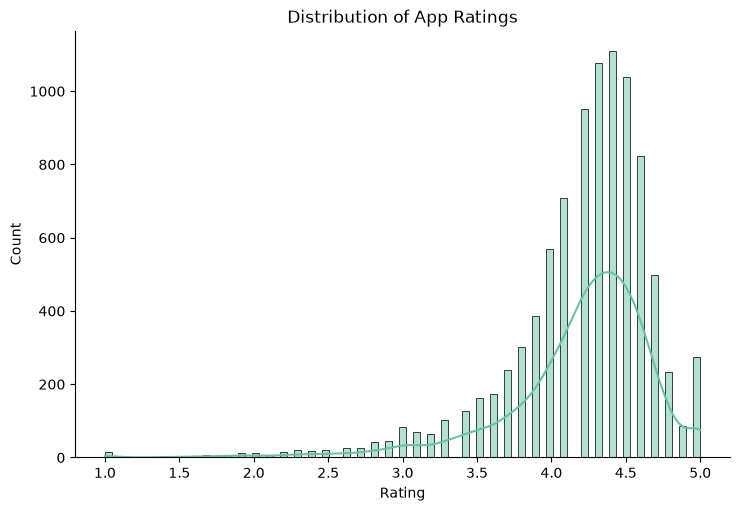

In [18]:
# Plot 1: Distribution of app ratings
sns.displot(data=df, x='Rating', kde=True, fill=True, height=5, aspect=1.5)
plt.title('Distribution of App Ratings')
plt.show()

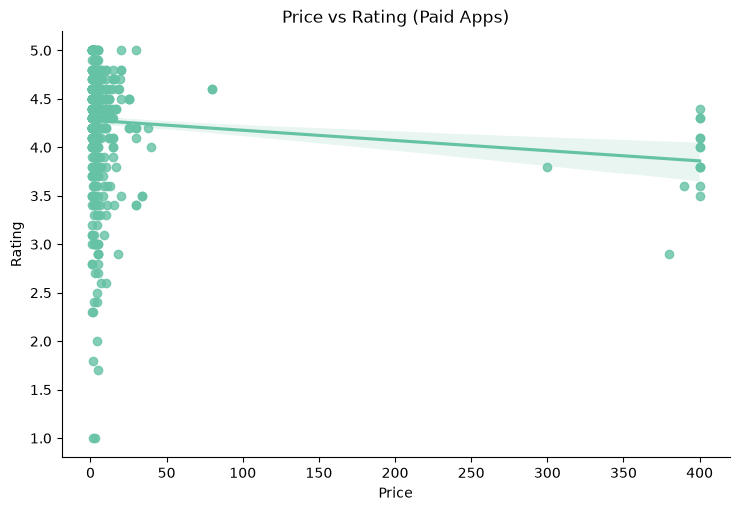

In [19]:
# Plot 2: Linear relationship between Price and Rating for paid apps
paid_apps = df[df['Type'] == 'Paid']
sns.lmplot(data=paid_apps, x='Price', y='Rating', height=5, aspect=1.5)
plt.title('Price vs Rating (Paid Apps)')
plt.show()

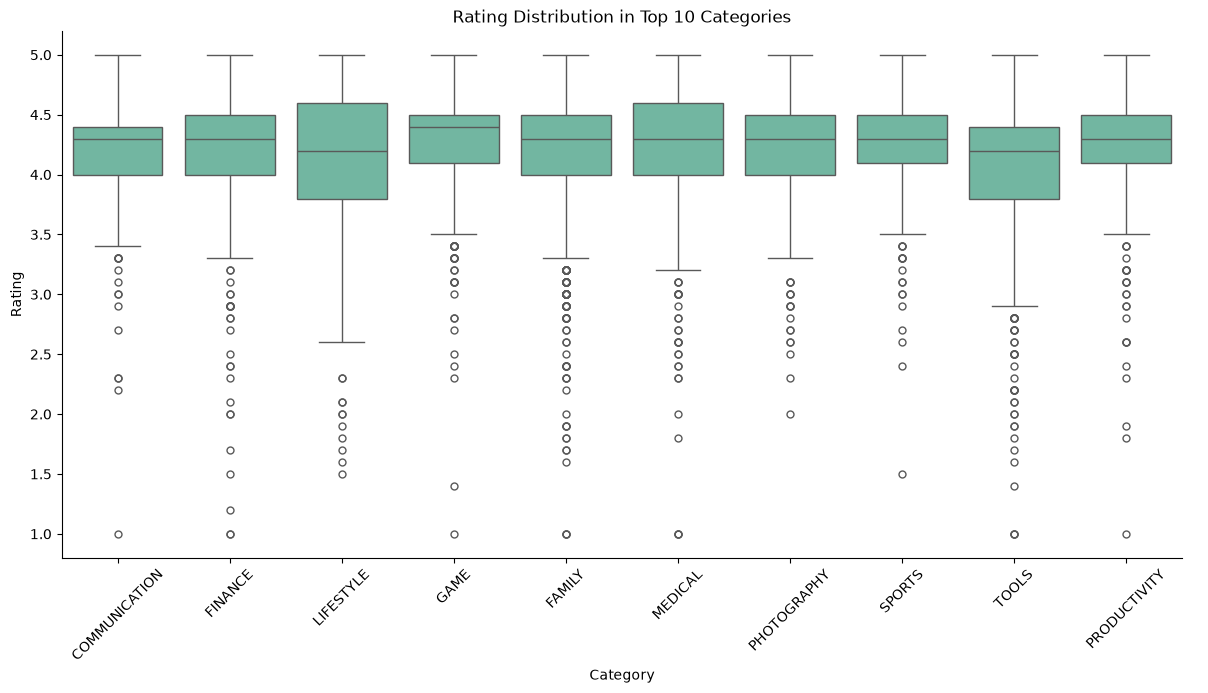

In [20]:
# Plot 3: Boxplot of ratings across the top 10 most frequent categories
top_categories = df['Category'].value_counts().head(10).index
df_top = df[df['Category'].isin(top_categories)]

sns.catplot(data=df_top, x='Category', y='Rating', kind='box', height=6, aspect=2)
plt.xticks(rotation=45)
plt.title('Rating Distribution in Top 10 Categories')
plt.show()

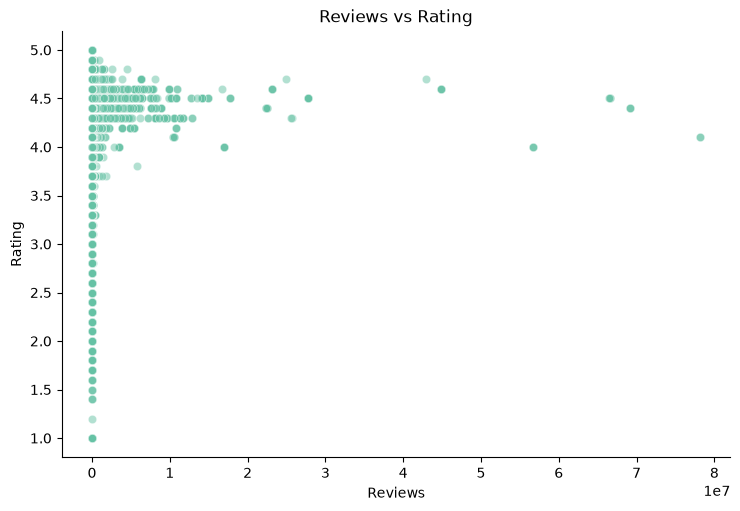

In [21]:
# Plot 4: Scatter plot showing the relationship between number of reviews and rating
sns.relplot(data=df, x='Reviews', y='Rating', kind='scatter', alpha=0.5, height=5, aspect=1.5)
plt.title('Reviews vs Rating')
plt.show()

## Send us the Result (Maktabkhoone)